# Explainable Constraint Solving — ACP 2026 Summer School

Runnable notebook that demonstrates the different algorithms in the slides.

Note that some use the upstream cpmpy.tools.explain, while others have less mature implementations that live in the XCP-explain repo.

Feel free to play with it!


In [ ]:
# Colab / fresh checkout
import os, sys
if os.path.isfile("factory.py"):
    print("Reusing local checkout")
    root = os.getcwd()
else:
    print("Cloning from GitHub")
    root = "/tmp/XCP-explain"
    ! git clone https://github.com/CPMpy/XCP-explain.git {root}
! pip install -q -r {root}/requirements.txt
if root not in sys.path:
    sys.path.insert(0, root)


Reusing local checkout


In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
import time
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

import cpmpy as cp
import cpmpy.tools.explain as cpx
from cpmpy import SolverLookup

from visualize import *
from factory import NurseSchedulingFactory
from read_data import get_data

names = SolverLookup.solvernames()
print("Available solvers:", names)

if "root" not in dir():
    root = os.getcwd()

sat_solver = "pumpkin" if "pumpkin" in names else "ortools"
hs_solver = "gurobi" if "gurobi" in names else "ortools"
print(f"sat_solver={sat_solver}, hs_solver={hs_solver}")

def draw(g, **kwargs):
    plt.figure(figsize=(4, 4))
    nx.draw_circular(g, width=4, node_size=400, **kwargs)
cmap = ["black", "yellow", "cyan", "lightgreen", "blue"]

def graph_highlight(graph, cons, dotted=False, **kwargs):
    edges = []
    for c in cons:
        n1, n2 = c.args
        if n1.name == "max":
            continue
        a = int(re.search(r"\[[0-9]*\]", str(n1)).group()[1:-1])
        b = int(re.search(r"\[[0-9]*\]", str(n2)).group()[1:-1])
        edges.append((a, b))
    colors = ["red" if (a, b) in edges else "black" for (a, b) in graph.edges()]
    linestyles = ["dotted" if c == "red" and dotted else "solid" for c in colors]
    return draw(graph, edge_color=colors, style=linestyles, **kwargs)


Available solvers: ['ortools', 'pumpkin']
sat_solver=pumpkin, hs_solver=ortools


## 1. Introduction to XCP — graph coloring

Toy example, graph coloring:

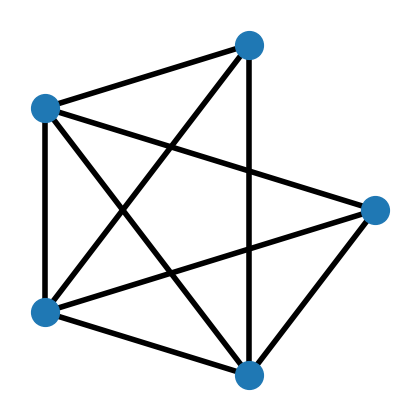

In [3]:
G = nx.fast_gnp_random_graph(5, 0.8, seed=0)
draw(G)

In [4]:
def graph_coloring(G, max_colors=None):
    n = G.number_of_nodes()
    if max_colors is None:
        max_colors = n
    x = cp.intvar(1, max_colors, shape=n, name="x")
    m = cp.Model(
        [x[i] != x[j] for i, j in G.edges()],
        minimize=cp.max(x),
    )
    return m, x

Lets color the graph...

ExitStatus.OPTIMAL (0.011742368000000001 seconds)
Found optimal coloring with 4 colors


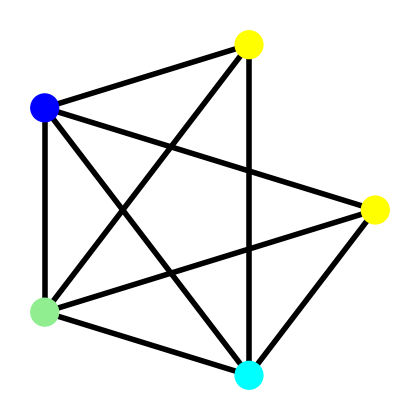

In [5]:
m, nodes = graph_coloring(G, max_colors=None)
if m.solve():
    print(m.status())
    print(f"Found optimal coloring with {m.objective_value()} colors")
    draw(G, node_color=[cmap[v.value()] for v in nodes])
else:
    print("No solution found.")


Why do we need at least 4 colors?

Deductive explanation: pinpoint to constraints causing this fact

UNSAT is caused by the following constraint(s):


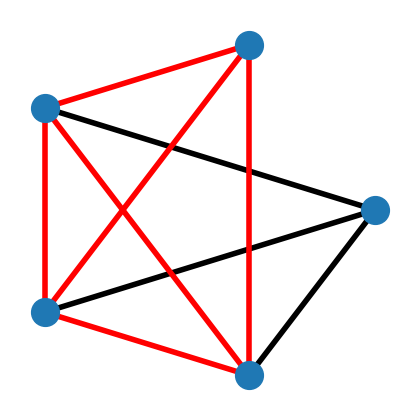

In [6]:
m, nodes = graph_coloring(G, max_colors=3)
if m.solve() is False:
    conflict = cpx.mus(m.constraints)
    print("UNSAT is caused by the following constraint(s):")
    graph_highlight(G, conflict)

Why do we need at least 4 colors?

Counterfactual explanation: pinpoint to constraint changes that would allow, e.g. 3 colors

UNSAT can be resolved by removing the following constraint(s):


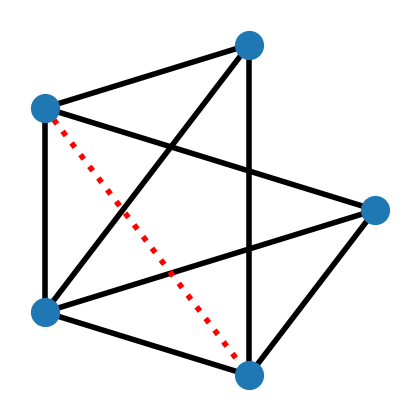

In [7]:
m, nodes = graph_coloring(G, max_colors=3)
if m.solve() is False:
    corr = cpx.mcs(m.constraints)
    print("UNSAT can be resolved by removing the following constraint(s):")
    graph_highlight(G, corr, dotted=True)

Can now compute the counterfactual solution:

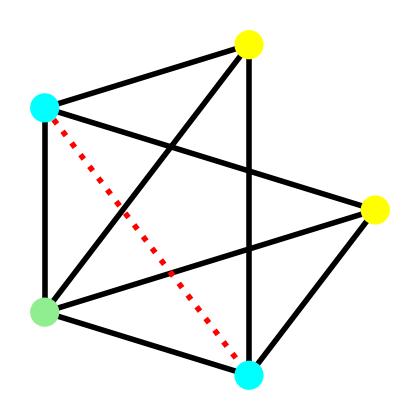

In [8]:
m2 = cp.Model([c for c in m.constraints if c not in corr])
m2.solve()
graph_highlight(G, corr, node_color=[cmap[n.value()] for n in nodes], dotted=True)

## 2. Deductive explanations for UNSAT

Instance 1 from the nurse rostering benchmarks.

In [9]:
instance = os.path.join(root, "Benchmarks/Instance1.txt")  # http://www.schedulingbenchmarks.org/nrp/data/Instance1.txt
data = get_data(instance)

print("Nr of days to schedule:", data.horizon)
print("Nr of shift types:", len(data.shifts))
print("Staff holidays:")
pd.merge(data.days_off, data.staff[["# ID", "name"]], left_on="EmployeeID", right_on="# ID", how="left")


Nr of days to schedule: 14
Nr of shift types: 1
Staff holidays:


,EmployeeID,DayIndex,# ID,name
0,A,0,A,Megan
1,B,5,B,Katherine
2,C,8,C,Robert
3,D,2,D,Jonathan
4,E,9,E,William
5,F,5,F,Richard
6,G,1,G,Kristen
7,H,7,H,Kevin


An example solution (day requirements and day preferences as soft constraints)

In [10]:
factory = NurseSchedulingFactory(data)
model, nurse_view = factory.get_optimization_model()
model.solve()
visualize(nurse_view.value(), factory)

Model nurse rostering problem as decision problem (no objective).

All constraints and day preferences are hard constraints.

In [11]:
factory = NurseSchedulingFactory(data)
model, nurse_view = factory.get_decision_model()
print("Decision model SAT?", model.solve())

Decision model SAT? False


In [12]:
print(f"Model has {len(model.constraints)} constraints:")
for c in model.constraints:
    print(c, " "*(60-len(str(c))), c.__repr__())

Model has 360 constraints:
Megan can work at most 14 D-shifts                            count([roster[0,0],roster[0,1],roster[0,2],roster[0,3],roster[0,4],roster[0,5],roster[0,6],roster[0,7],roster[0,8],roster[0,9],roster[0,10],roster[0,11],roster[0,12],roster[0,13]],1) <= 14
Katherine can work at most 14 D-shifts                        count([roster[1,0],roster[1,1],roster[1,2],roster[1,3],roster[1,4],roster[1,5],roster[1,6],roster[1,7],roster[1,8],roster[1,9],roster[1,10],roster[1,11],roster[1,12],roster[1,13]],1) <= 14
Robert can work at most 14 D-shifts                           count([roster[2,0],roster[2,1],roster[2,2],roster[2,3],roster[2,4],roster[2,5],roster[2,6],roster[2,7],roster[2,8],roster[2,9],roster[2,10],roster[2,11],roster[2,12],roster[2,13]],1) <= 14
Jonathan can work at most 14 D-shifts                         count([roster[3,0],roster[3,1],roster[3,2],roster[3,3],roster[3,4],roster[3,5],roster[3,6],roster[3,7],roster[3,8],roster[3,9],roster[3,10],roster[3,11],roste

### Deletion-based MUS


#### Naive implementation:

In [13]:
t0 = time.time()
subset_naive = cpx.mus_naive(model.constraints)
print(f"Naive MUS took {time.time()-t0:.2f}s ({len(subset_naive)} constraints)")

Naive MUS took 12.06s (3 constraints)


#### Assumption-based implementation (default in CPMpy)

In [14]:
t0 = time.time()
subset = cpx.mus(model.constraints, solver=sat_solver)
print(f"Assumption-based MUS took {time.time()-t0:.2f}s ({len(subset)} constraints)")

Assumption-based MUS took 0.14s (11 constraints)


#### UNSAT core from prooflog + assumption-based deletion

In [15]:
from explanations.pumpkin_core_fromproof import PumpkinProofCore
import tempfile

t0 = time.time()
proof_path = tempfile.NamedTemporaryFile(suffix=".drcp", delete=False).name
s = PumpkinProofCore(model, proof=proof_path)
assert s.solve() is False
core = s.get_core()
print(f"Proof-based core took {time.time()-t0:.2f}s ({len(core)} constraints in core)")

res = cpx.mus(core, solver=sat_solver)
print(f"Proof-based core + MUS took {time.time()-t0:.2f}s ({len(res)} constraints)")


Proof-based core took 0.13s (5 constraints in core)
Proof-based core + MUS took 0.14s (3 constraints)


### DRCP proof over user-level constraints. 

Full prooflog vs trimmed


1) alldifferent(x,y)
2) (x) == (z)
3) x <= 1
4) (a) + (b) <= 15
5) y == 1
6) (x) >= (y)


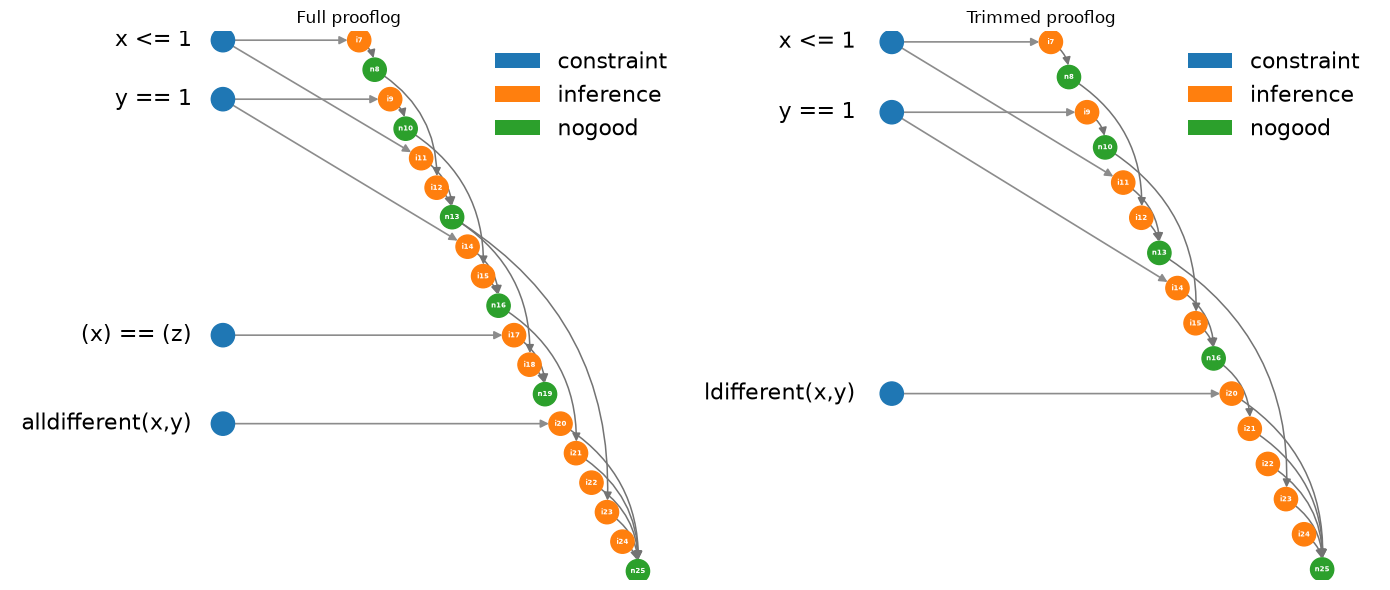

In [16]:
x, y, z = cp.intvar(1, 2, shape=3, name=list("xyz"))
a, b = cp.intvar(0, 10, shape=2, name=list("ab"))
proof_model = cp.Model(
    cp.AllDifferent([x, y]),
    x == z,
    x <= 1,
    a + b <= 15,
    y == 1,
    x >= y,
)
for i, c in enumerate(proof_model.constraints, 1):
    print(f"{i}) {c}")

proof_path = tempfile.NamedTemporaryFile(suffix=".drcp", delete=False).name
s = PumpkinProofCore(proof_model, proof=proof_path)
assert s.solve() is False

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
s.visualize_proof(trimmed=False, ax=axes[0])
axes[0].set_title("Full prooflog")
s.visualize_proof(trimmed=True, ax=axes[1])
axes[1].set_title("Trimmed prooflog")
plt.tight_layout()
plt.show()


### Enumerating MUSes with MARCO


In [17]:
t0 = time.time()
cnt = 0
for (kind, sset) in cpx.marco(model.constraints, solver=sat_solver, map_solver=sat_solver):
    if kind == "MUS":
        print("M", end="")
        cnt += 1
    else:
        print(".", end="")
    if time.time() - t0 > 15:
        break
print(f"\nFound {cnt} MUSes in {time.time() - t0:.2f}s")


..M.....MM.....M...M....M..................................MM.............M.....M..M.....M.M..M..M..M.M..M...MM...........M....................MM............M..................M......M............M..MM...M.............M...M...................................M...M.......M........M.....M..M...............M....
Found 39 MUSes in 15.03s


### Preferred MUS with QuickXplain


In [18]:
t0 = time.time()
subset = cpx.quickxplain(sorted(model.constraints, key=lambda c: -len(str(c))), solver=sat_solver)
print(f"Prefer complex (long len(str)) constraints took {time.time()-t0:.2f}s ({len(subset)} constraints)")

t0 = time.time()
subset = cpx.quickxplain(sorted(model.constraints, key=lambda c: len(str(c))), solver=sat_solver)
print(f"Prefer short (short len(str)) constraints took {time.time()-t0:.2f}s ({len(subset)} constraints)")
visualize_constraints(subset, nurse_view, factory)


Prefer complex (long len(str)) constraints took 0.54s (39 constraints)
Prefer short (short len(str)) constraints took 0.15s (3 constraints)


### Smallest MUS (optimal MUS / OUS)


In [19]:
t0 = time.time()
small_subset = cpx.optimal_mus(model.constraints, solver=sat_solver, hs_solver=hs_solver)
print(f"Optimal MUS took {time.time()-t0:.2f}s ({len(small_subset)} constraints)")

for cons in small_subset:
    print("-", cons)
visualize_constraints(small_subset, nurse_view, factory)

Optimal MUS took 0.83s (3 constraints)
- Robert has a day off on Tue 2
- Richard requests not to work shift D on Tue 2
- Shift D on Tue 2 must be covered by 7 nurses out of 8


## 3a. Deductive explanations for SAT problems

Simplest next sudoku step with OCUS

In [20]:
grid = np.array([
    [6,9,4, 0,0,1, 0,0,0],
    [0,0,3, 0,2,0, 0,4,5],
    [2,7,0, 0,6,0, 0,0,0],
    [0,0,1, 0,0,4, 0,7,0],
    [0,2,6, 0,8,7, 0,9,3],
    [3,5,7, 0,0,0, 4,0,2],
    [0,6,9, 0,0,0, 0,0,1],
    [1,3,0, 6,0,0, 7,0,0],
    [0,0,0, 1,0,2, 0,0,0],
])
def model_sudoku(grid):
    grid = np.array(grid)
    e = cp.intvar(1, 9, shape=grid.shape, name="e")
    cons = []
    cons += [cp.AllDifferent(row) for row in e]
    cons += [cp.AllDifferent(col) for col in e.T]
    for i in range(0, 9, 3):
        for j in range(0, 9, 3):
            cons += [cp.AllDifferent(e[i:i+3, j:j+3])]
    givens = [e[i, j] == v for (i, j), v in np.ndenumerate(grid) if int(v) != 0]
    return cp.Model(cons + givens), e
m, e = model_sudoku(grid)
assert m.solve()
sol = e.value()
print(f"Found sudoku's unique solution in {m.status().runtime}")

Found sudoku's unique solution in 0.0031601460000000004


In [21]:
rules = [c for c in m.constraints if getattr(c, "name", None) == "alldifferent"]
givens = [e[i, j] == v for (i, j), v in np.ndenumerate(grid) if int(v) != 0]
neg_lits = [
    ~(e[i, j] == sol[i, j])
    for i in range(9) for j in range(9) if grid[i, j] == 0
]
step = cpx.ocus(
    soft=rules + neg_lits,
    hard=givens,
    meta_constraint=(cp.sum(neg_lits) == 1),
    solver=sat_solver,
    hs_solver=hs_solver,
)
print(f"Simplest next step ({len(step)} constraints):")
for c in step:
    print("-", c)
subfacts = cpx.mus(givens, hard=step)
print(f"with {len(subfacts)} facts:")
for f in subfacts:
    print("-", f)
# TODO: nicer grid visu... e.g. a dataframe with coloring


Simplest next step (3 constraints):
- alldifferent(e[4,0],e[4,1],e[4,2],e[4,3],e[4,4],e[4,5],e[4,6],e[4,7],e[4,8])
- alldifferent(e[3,0],e[3,1],e[3,2],e[4,0],e[4,1],e[4,2],e[5,0],e[5,1],e[5,2])
- not(e[4,0] == 4)
with 8 facts:
- e[5,1] == 5
- e[4,2] == 6
- e[4,5] == 7
- e[4,4] == 8
- e[3,2] == 1
- e[4,7] == 9
- e[4,8] == 3
- e[4,1] == 2


## 3b. Deductive explanations for OPT problems

What constraints causes that there is no better solution?
- Reduce to UNSAT problem:
- Add better-than-optimal objective value as constraint
- Then use dedictive explanation techniques for UNSAT! (e.g. MUS)

In [22]:
# optimal solution:
model, nurse_view = factory.get_optimization_model()
model.solve()
print("Optimal penalty:", model.objective_value())

# reduce to UNSAT problem:
dmodel = cp.Model(model.constraints)
dmodel += (model.objective_ < model.objective_value())
assert dmodel.solve() is False

# compute MUS of new problem:
t0 = time.time()
core = cpx.mus(dmodel.constraints, solver=sat_solver)
print(f"OPT MUS length {len(core)} in {time.time()-t0:.2f}s")
visualize_constraints(core, nurse_view, factory)

Optimal penalty: 607
OPT MUS length 97 in 31.36s


It is indeed typically a large MUS when explain optimality...


Stepwise explanation of the jobshop problem, from a prooflog (CP 2026).

TODO: Code is missing from the notebook, please find it at: https://github.com/ML-KULeuven/Stepwise-ComplexSearch

## 4a. Counterfactual explanations for UNSAT

In [ ]:
start_interactive_mode = False

# Back to the UNSAT decision model for counterfactual UNSAT
factory = NurseSchedulingFactory(data)
model, nurse_view = factory.get_decision_model()
assert model.solve() is False

if start_interactive_mode:
    def cb_visu(core):
        display(visualize_constraints(core, nurse_view, factory))

    from explanations.diagnosis import diagnose, diagnose_optimal
    corr_subset = diagnose(model.constraints, solver="pumpkin", callback=cb_visu)
    clear_output()
    print("Resolved.")

Resolved.


### MaxCSP solving (optimisation of largest MSS/smallest MCS)

In [24]:
# Max-CSP: largest MSS
indicators = cp.boolvar(shape=len(model.constraints), name="ind")
ind_model = cp.Model(indicators.implies(model.constraints))
ind_model.maximize(indicators.sum())

t0 = time.time()
assert ind_model.solve() is True
print(f"Optimal MSS took {time.time()-t0:.2f}s ({ind_model.objective_value()} out of {len(ind_model.constraints)} constraints)")

Optimal MSS took 0.25s (356 out of 360 constraints)


In [25]:
# Corresponding smallest MCS
print(f"Removed these {len(model.constraints) - ind_model.objective_value()} constraints:")
for c in model.constraints:
    if c.value() is False:
        print("-", c)
        
print("Resulting solution:")
visualize(nurse_view.value(), factory)

Removed these 4 constraints:
- Robert has a day off on Tue 2
- Richard requests not to work shift D on Tue 2
- Shift D on Sat 1 must be covered by 5 nurses out of 8
- Shift D on Sun 1 must be covered by 5 nurses out of 8
Resulting solution:


### Grow-based MCS

In [26]:
t0 = time.time()
corr_subset = cpx.mcs(model.constraints)

print(f"Grow-based MCS took {time.time()-t0:.2f}s ({len(corr_subset)} constraints)")
visualize_constraints(corr_subset, nurse_view, factory)

Grow-based MCS took 0.31s (4 constraints)


Lexicographic order over constraints: FastDiag is the MCS counterpart of QuickXplain

In [27]:
from explanations.diagnosis import fastdiag_naive

t0 = time.time()
subset = fastdiag_naive(sorted(model.constraints, key=lambda c: len(str(c))), solver="ortools")

print(f"FastDiag (prefer short len(str)) took {time.time()-t0:.2f}s ({len(subset)} constraints)")
for c in subset:
    print("-", c)
#visualize_constraints(subset, nurse_view, factory)

FastDiag (prefer short len(str)) took 2.38s (12 constraints)
- Kevin requests to work shift D on Thu 2
- Kevin requests to work shift D on Wed 2
- Kristen should work at most 1 weekends
- Richard should work at most 1 weekends
- William should work at most 1 weekends
- Kevin should work at most 1 weekends
- Megan should work at most 1 weekends
- Jonathan has a day off on Wed 1
- Kristen has a day off on Tue 1
- Richard has a day off on Sat 1
- Robert has a day off on Tue 2
- Kevin has a day off on Mon 2


### Slack-based relaxations

Can chose the objective function in different ways...

#### Minimize total slack

In [28]:
slack_model, slack_nurse_view, slack_over, slack_under = factory.get_slack_model()
slack_model.minimize(cp.sum(slack_under) + cp.sum(slack_over))

assert slack_model.solve()

style = visualize(slack_nurse_view.value(), factory, highlight_cover=True)
style.data.loc["Slack under"] = list(slack_under.value()) + [" ", " "]
style.data.loc["Slack over"] = list(slack_over.value()) + [" ", " "]
display(style)

#### Minimize number of non-zero slacks

In [29]:
slack_model.minimize(cp.sum(slack_under != 0) + cp.sum(slack_over != 0))
assert slack_model.solve()

style = visualize(slack_nurse_view.value(), factory, highlight_cover=True)
style.data.loc["Slack under"] = list(slack_under.value()) + [" "] * 2
style.data.loc["Slack over"] = list(slack_over.value()) + [" "] * 2
display(style)

### A lexicographic combination

In [30]:
slack = cp.cpm_array(np.append(slack_under, slack_over))
obj1 = cp.max(slack)       # minimize max violation
obj2 = cp.sum(slack != 0)  # minimize nb of violations
obj3 = cp.sum(slack)       # minimize global violation

slack_model.minimize(10000 * obj1 + 1000 * obj2 + obj3) # multi-objective optimization

assert slack_model.solve()
style = visualize(slack_nurse_view.value(), factory, highlight_cover=True)
style.data.loc["Slack under"] = list(slack_under.value()) + [" "]*2
style.data.loc["Slack over"] = list(slack_over.value()) + [" "]*2
display(style)

## 4b. Counterfactual Explanations for SAT problems

Example where the user asks: "What if Y instead of X?"

In [31]:
# William is set to work the first Saturday
model_pre = slack_model.copy()
model_pre.solve()
assert nurse_view[4, 5].value()

# What if William does not work the first Saturday?
model_post = slack_model.copy()
model_post += (slack_nurse_view[4, 5] == 0)
assert model_post.solve()

print("Total penalty:", model_post.objective_value(), "versus", model_pre.objective_value(), "before")
style = visualize(slack_nurse_view.value(), factory, highlight_cover=True)
style.data.loc["Slack under"] = list(slack_under.value()) + [" "] * 2
style.data.loc["Slack over"] = list(slack_over.value()) + [" "] * 2
display(style)


Total penalty: 36016 versus 36016 before


## 4c. Counterfactual Explanations for OPT problems

### How to (optimally) change the solution having Y instead of X? 

In [32]:
model, nurse_view = factory.get_optimization_model()

assert model.solve()
opt_sol = nurse_view.value()
opt_value = model.objective_value()

print("Total penalty:", opt_value)
visualize(opt_sol, factory)

Total penalty: 607


Robert __does not__ want to work on 1st saturday

In [33]:
Y = nurse_view[2,5] == 0 # The foil is that Robert does not want to work on 1st saturday
mmodel = model.copy()
mmodel += Y 

assert mmodel.solve()
print("Total penalty:", mmodel.objective_value(), "was:", opt_value)

style = highlight_changes(nurse_view.value(), opt_sol, factory)
display(style)

Total penalty: 608 was: 607


### Corrective actions over the objective function coefficients.

The user asks: "What coefficients need to change so that Y becomes an optimal solution instead of X?"

In [34]:
model, nurse_view = factory.get_optimization_model()

assert model.solve()
opt_sol = nurse_view.value()
opt_value = model.objective_value()

print("Total penalty:", opt_value)
visualize(opt_sol, factory)

Total penalty: 607


Let's check Robert's preferences

In [35]:
nurse = "Robert"
 
for (w,pref) in zip(*model.objective_.args):
    if nurse in str(pref):
        print('\033[1m' if pref.value() else '\033[0m', f"{pref.value()} \t Penalty:{w} \t{pref} \t")

 False 	 Penalty:1 	Deny Robert's request to work shift D on Mon 1 	
 False 	 Penalty:1 	Deny Robert's request to work shift D on Tue 1 	
 False 	 Penalty:1 	Deny Robert's request to work shift D on Wed 1 	
 True 	 Penalty:1 	Deny Robert's request to work shift D on Thu 1 	
 True 	 Penalty:1 	Deny Robert's request to work shift D on Fri 1 	
 False 	 Penalty:1 	Deny Robert's request not to work shift D on Sat 2 	
 False 	 Penalty:1 	Deny Robert's request not to work shift D on Sun 2 	


In [36]:
from explanations.counterfactual import inverse_optimize

nurse = "Robert"
desc = "Deny Robert's request to work shift D on Fri 1"
weight, d_on_fri1 = next((w, pref) for w, pref in zip(*model.objective_.args) if str(pref) == desc)
print(f"{d_on_fri1.value()}\tPenalty:{weight}\t{d_on_fri1}")

foil = {d_on_fri1: False}
other_prefs = [(w, pref) for w, pref in zip(*model.objective_.args) if nurse in str(pref) and str(pref) != desc]
print("Foil:", foil)

ov = model.objective_value()
new_obj = inverse_optimize(
    model=model, minimize=True,
    user_sol=foil,
    allowed_to_change=set(p[1] for p in other_prefs),
)
print(f"Done! Found solution with total penalty {new_obj.value()}, was {ov}")
print(f"{nurse}'s new preferences:")
for w, pref in zip(*new_obj.args):
    if nurse in str(pref):
        print(f"Penalty {w}: {pref}")

model.minimize(new_obj)
assert model.solve()
print("Total penalty with new weights:", model.objective_value())
visualize(nurse_view.value(), factory)


True	Penalty:1	Deny Robert's request to work shift D on Fri 1
Foil: {roster[2,4] != 1: False}
Done! Found solution with total penalty 608, was 607
Robert's new preferences:
Penalty 1: Deny Robert's request to work shift D on Mon 1
Penalty 1: Deny Robert's request to work shift D on Tue 1
Penalty 1: Deny Robert's request to work shift D on Wed 1
Penalty 2: Deny Robert's request to work shift D on Thu 1
Penalty 1: Deny Robert's request to work shift D on Fri 1
Penalty 1: Deny Robert's request not to work shift D on Sat 2
Penalty 1: Deny Robert's request not to work shift D on Sun 2
Total penalty with new weights: 608
